This notebook selects and tunes the regressor that predicts each player's MVP vote share. Only seasons before 2019 are used; 2019–2025 is the hold-out, scored once in `notebooks/final.ipynb`.

Each candidate model is tuned with forward-chaining cross-validation (`utils.forward_chaining_splits`: train on all earlier seasons, validate on the next one), then scored on how often its top prediction was the real MVP. The tuned models are saved to `misc/joblib/`.

Exploratory work (quasi-binomial and conditional logit models, the visuals, and experiments with past-MVP features and training windows) is in `regressor_exploration.ipynb`.

In [7]:
import sys
from pathlib import Path
import os
os.environ['OMP_NUM_THREADS'] = '1'   #HGBR runs ~15x faster single-threaded on our small data (macOS threading overhead)
import numpy as np
import pandas as pd
import statsmodels.api as sm
import joblib

pd.set_option('display.max_columns', None)

#find the project root
ROOT=Path.cwd()
while not (ROOT / ".git").exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

OUT = ROOT / 'misc'
OUT.mkdir(parents=True, exist_ok=True)   #creates misc/ if it doesn't exist
(OUT / 'joblib').mkdir(parents=True, exist_ok=True)

from config import START_YEAR, END_YEAR, HOLDOUT_START, MP_THRESHOLD, MIN_GAMES_SHARE, MIN_MP
import utils

df_tot=utils.player_stat_dataframe(START_YEAR, END_YEAR)
df_tot.shape

RUN_TUNING = False     #set to False after the first run, so run-all skips the search (results are saved to csv)

In [2]:
df_holdout=df_tot[df_tot['Year'] >= HOLDOUT_START].copy() #locked away until the very end
df_tot=df_tot[df_tot['Year'] < HOLDOUT_START].copy() #everything below uses only this
print(df_tot['Year'].max(), "last development season") #should be 2018

2018 last development season


In [3]:
#traded players: utils already keeps only the 2TM/3TM season-total row; this flag and filter are a safety net in case that changes
is_total=df_tot['Team'].str.endswith('TM')
df_tot['TradedMidSeason']=is_total.groupby([df_tot['Year'], df_tot['Code']]).transform('any').astype(int)

#season length = most games any single-team player played that season (50 in 1998-99, 66 in 2011-12, ...)
season_games=df_tot[~is_total].groupby('Year')['G'].max()
df_tot['SeasonG']=df_tot['Year'].map(season_games)
df_tot['GP%']=df_tot['G'] / df_tot['SeasonG']      #recomputed: the loader divides by the most games in the file, which a traded player's total can exceed

#keep one row per player-season: single-team players keep their row, traded players only keep their total row
season_rows=df_tot[(df_tot['TradedMidSeason']== 0) | is_total]

#MVP eligibility, step 1 of the two-step model:the CBA rule since 2023-24 is 65 games with 20+ minutes.
#This is applied to EVERY season, scaled to season length(40 of 50 games in 1998-99, 53 of 66 in 2011-12..)because voters already kinda behaved this way (see the check in the next cell).
#Our data only has season averages, so 20+ mins == MP >=20 per game, and the rule's injury exceptions aren't modeled.-->could keep 60+ games if we want to account fir injuries etc
min_games=np.ceil(MIN_GAMES_SHARE * season_rows['SeasonG'])
eligible=(season_rows['G'] >= min_games) & (season_rows['MP'] >= MIN_MP)

data=season_rows[eligible].reset_index(drop=True)

print(data.shape)
print(data.duplicated(['Year', 'Code']).sum(), "duplicate player-seasons")
print((data['MVPVS'] > 0).sum(), "vote-getter rows")
print(data.groupby('Year')['MVP'].sum().eq(1).all(), "every season still has its MVP")

assert (data['MVP'] == (data['MVPVS'] == data.groupby('Year')['MVPVS'].transform('max'))).all(), 'MVP flag does not match the top vote share'

(6287, 39)
0 duplicate player-seasons
610 vote-getter rows
True every season still has its MVP


In [4]:
#check: which vote-getters does the rule remove, and did any of them finish top 3?
removed=season_rows[~eligible & (season_rows['MVPVS'] > 0)]
vote_rank=season_rows.groupby('Year')['MVPVS'].rank(ascending=False, method='min')
share=removed['MVPVS'].sum() / season_rows['MVPVS'].sum() * 100
print(len(removed), f'vote-getters removed, with {share:.1f}% of all vote share')
print((vote_rank[removed.index] <= 3).sum(), 'of them finished top 3')
removed.sort_values('MVPVS', ascending=False)[['Year', 'Player', 'G', 'SeasonG', 'MP', 'MVPVS']].head(10)

39 vote-getters removed, with 0.8% of all vote share
0 of them finished top 3


,Year,Player,G,SeasonG,MP,MVPVS
6138,1997,Shaquille O'Neal,60.0,82.0,36.3,0.268
1252,1984,Bernard King,55.0,82.0,37.5,0.090
5273,1995,Shaquille O'Neal,54.0,82.0,36.0,0.056
15803,2018,Joel Embiid,64.0,82.0,33.7,0.049
13327,2013,Chris Paul,62.0,82.0,35.0,0.036
7900,2001,Chris Webber,54.0,82.0,38.4,0.029
10,1980,Magic Johnson,37.0,82.0,37.1,0.026
3301,1990,Larry Bird,60.0,82.0,38.0,0.026
7902,2001,Allen Iverson,60.0,82.0,43.7,0.023
314,1981,Dan Roundfield,61.0,82.0,36.3,0.020


In [5]:
#now feature lists and within-season z-scores.
feature_sets = {
    'heatmap_8':        ['PTS', 'W%', 'FT', 'eFG%', 'TRB', 'AST', 'BLK', 'STL'],
    'candidates_10':    ['PTS', 'W%', 'FT', 'eFG%', 'DRB', 'AST', 'BLK', 'STL', 'GS', '3P'],
    'rf_recall_6':      ['PTS', 'W%', 'DRB', 'AST', 'BLK', 'STL'],
}
#rf_recall_6: best feature set for the Random Forest classifier (classifier.ipynb), chosen on development seasons only
all_feats=sorted(set().union(*feature_sets.values()))

#within-season z-score for each feature: (value - season mean) / season std, then check no NaNs
for col in all_feats:
    g=data.groupby('Year')[col]
    data[col + '_z']=(data[col] - g.transform('mean'))/g.transform('std')

print(data[[c + '_z' for c in all_feats]].isna().sum())

3P_z      0
AST_z     0
BLK_z     0
DRB_z     0
FT_z      0
GS_z      0
PTS_z     0
STL_z     0
TRB_z     0
W%_z      0
eFG%_z    0
dtype: int64


# Regressor testing
All three candidates use the candidates_10 stats (raw, not z-scored) on the eligible player pool, and are tuned with the same forward-chaining splits.

## HistGradientBoostingRegressor
The best model is saved to `misc/joblib/tuned_hgbr_model.joblib`

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

results_by_model = {}

tune_feats = feature_sets['candidates_10']
target = 'MVPVS'

train = data[data['Year'] < HOLDOUT_START]

X_tr, y_tr = train[tune_feats], train[target]


cv = list(utils.forward_chaining_splits(train.Year, min_train_years=10))


search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=29),
    param_distributions = {
    'loss': ('squared_error', 'poisson'),
    'learning_rate': (0.01, 0.03, 0.05),
    'max_iter': (100, 200),
    'max_depth': (2, 3, 4, None),
    'max_leaf_nodes': (7, 15, 31),
    'min_samples_leaf': (1,2,3,4,5),
    'l2_regularization': (0.0, 0.5, 1.0),
 },
    n_iter=200,
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=29,
)
search.fit(X_tr, y_tr)
joblib.dump(search.best_estimator_, str(ROOT/'misc/joblib/tuned_hgbr_model.joblib'), compress=3)

In [9]:
tmp_data = data.copy()
tmp_data['HGBR_pred'] = [0.0]*len(tmp_data)
model = search.best_estimator_
result = pd.DataFrame(columns=['Year','MVPVS','HGBR_pred','ActualWinner','PredictedWinner','Top3','Match'])
for chain in cv:
    model.fit(X_tr.iloc[chain[0]],y_tr.iloc[chain[0]])
    y_pred = model.predict(X_tr.iloc[chain[1]])
    tmp_data.loc[chain[1],'HGBR_pred'] = y_pred
    true_mvp = tmp_data.iloc[chain[1]].sort_values('MVPVS', ascending=False).iloc[0]
    pred_mvp = tmp_data.iloc[chain[1]].sort_values('HGBR_pred', ascending=False).iloc[0]
    top3 = list(tmp_data.iloc[chain[1]].sort_values('HGBR_pred', ascending=False).iloc[0:3].Player)
    tmp = pd.DataFrame({'Year': [int(true_mvp['Year'])], 
                   'MVPVS': [float(true_mvp['MVPVS'])], 
                   'HGBR_pred': [float(pred_mvp['HGBR_pred'])], 
                   'ActualWinner': [str(true_mvp['Player'])], 
                   'PredictedWinner': [str(pred_mvp['Player'])],
                   'Top3': [str(true_mvp['Player']) in top3],
                   'Match':[ (str(pred_mvp['Player']) == str(true_mvp['Player']))]}
                    )
    result = pd.concat([result,tmp],ignore_index=True)
    
tmp_data[(tmp_data.Year >= 1990)][['Player','MVPVS','HGBR_pred']]
print(f'{result.Match.sum()}/{len(result)}')
results_by_model['HGBR'] = result    

22/29


## AdaBoostRegressor
The best model is saved to `misc/joblib/tuned_ada_model.joblib`.

In [10]:
from scipy.stats import randint, loguniform
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RandomizedSearchCV

tune_feats = feature_sets['candidates_10']
target = 'MVPVS'

train = data[data['Year'] < HOLDOUT_START]

X_tr, y_tr = train[tune_feats], train[target]

ada = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(),  # use base_estimator= on sklearn < 1.2
    random_state=42,
)

param_distributions = {
    # AdaBoost's own params
    "n_estimators": randint(50, 1000),
    "learning_rate": loguniform(1e-3, 1.0),
    "loss": ["linear", "square", "exponential"],

    # Params of the base tree (note the estimator__ prefix)
    "estimator__max_depth": randint(1, 10),
    "estimator__min_samples_split": randint(2, 20),
    "estimator__min_samples_leaf": randint(1, 20),
    "estimator__max_features": [None, "sqrt", "log2"],
}

search = RandomizedSearchCV(
    ada,
    param_distributions=param_distributions,
    n_iter=50,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

search.fit(X_tr, y_tr)
print(search.best_params_)
print(-search.best_score_)  # RMSE
joblib.dump(search.best_estimator_, str(ROOT/'misc/joblib/tuned_ada_model.joblib'), compress=3)

Fitting 29 folds for each of 50 candidates, totalling 1450 fits
{'estimator__max_depth': 9, 'estimator__max_features': None, 'estimator__min_samples_leaf': 9, 'estimator__min_samples_split': 4, 'learning_rate': np.float64(0.0010491954332267905), 'loss': 'exponential', 'n_estimators': 698}
0.05135911325384118


['/Users/ntyagi/Desktop/MVP Predictions/fall-2026-nba-mvp-prediction/misc/joblib/tuned_ada_model.joblib']

In [11]:
tmp_data = data.copy()
tmp_data['Ada_pred'] = [0.0]*len(tmp_data)
model = search.best_estimator_
result = pd.DataFrame(columns=['Year','MVPVS','Ada_pred','ActualWinner','PredictedWinner','Top3','Match'])
for chain in cv:
    model.fit(X_tr.iloc[chain[0]],y_tr.iloc[chain[0]])
    y_pred = model.predict(X_tr.iloc[chain[1]])
    tmp_data.loc[chain[1],'Ada_pred'] = y_pred
    true_mvp = tmp_data.iloc[chain[1]].sort_values('MVPVS', ascending=False).iloc[0]
    pred_mvp = tmp_data.iloc[chain[1]].sort_values('Ada_pred', ascending=False).iloc[0]
    top3 = list(tmp_data.iloc[chain[1]].sort_values('Ada_pred', ascending=False).iloc[0:3].Player)
    tmp = pd.DataFrame({'Year': [int(true_mvp['Year'])], 
                   'MVPVS': [float(true_mvp['MVPVS'])], 
                   'Ada_pred': [float(pred_mvp['Ada_pred'])], 
                   'ActualWinner': [str(true_mvp['Player'])], 
                   'PredictedWinner': [str(pred_mvp['Player'])],
                   'Top3': [str(true_mvp['Player']) in top3],
                   'Match':[ (str(pred_mvp['Player']) == str(true_mvp['Player']))]}
                    )
    result = pd.concat([result,tmp],ignore_index=True)
    

print(f'{result.Match.sum()}/{len(result)}')
results_by_model['AdaBoost'] = result  

22/29


## GradientBoostingRegressor
The best model is saved to `misc/joblib/tuned_gbr_model.joblib`.

In [12]:
from scipy.stats import randint, uniform, loguniform
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

tune_feats = feature_sets['candidates_10']
target = 'MVPVS'

train = data[data['Year'] < HOLDOUT_START]

X_tr, y_tr = train[tune_feats], train[target]

gbr = GradientBoostingRegressor(random_state=42)

param_distributions = {
    # Boosting params
    "n_estimators": randint(100, 1000),
    "learning_rate": loguniform(1e-3, 0.3),
    "subsample": uniform(0.5, 0.5),          # samples from 0.5 to 1.0
    "loss": ["squared_error", "absolute_error", "huber"],

    # Tree params
    "max_depth": randint(2, 8),
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 20),
    "max_features": [None, "sqrt", "log2"],
}

search = RandomizedSearchCV(
    gbr,
    param_distributions=param_distributions,
    n_iter=50,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

search.fit(X_tr, y_tr)
print(search.best_params_)
print(-search.best_score_)  # RMSE

joblib.dump(search.best_estimator_, str(ROOT/'misc/joblib/tuned_gbr_model.joblib'), compress=3)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
{'learning_rate': np.float64(0.08138233922650512), 'loss': 'squared_error', 'max_depth': 3, 'max_features': 'log2', 'min_samples_leaf': 9, 'min_samples_split': 8, 'n_estimators': 300, 'subsample': np.float64(0.811649063413779)}
0.054076310643261793


['/Users/ntyagi/Desktop/MVP Predictions/fall-2026-nba-mvp-prediction/misc/joblib/tuned_gbr_model.joblib']

In [13]:
tmp_data = data.copy()
tmp_data['GBR_pred'] = [0.0]*len(tmp_data)
model = search.best_estimator_
result = pd.DataFrame(columns=['Year','MVPVS','GBR_pred','ActualWinner','PredictedWinner','Top3','Match'])
for chain in cv:
    model.fit(X_tr.iloc[chain[0]],y_tr.iloc[chain[0]])
    y_pred = model.predict(X_tr.iloc[chain[1]])
    tmp_data.loc[chain[1],'GBR_pred'] = y_pred
    true_mvp = tmp_data.iloc[chain[1]].sort_values('MVPVS', ascending=False).iloc[0]
    pred_mvp = tmp_data.iloc[chain[1]].sort_values('GBR_pred', ascending=False).iloc[0]
    top3 = list(tmp_data.iloc[chain[1]].sort_values('GBR_pred', ascending=False).iloc[0:3].Player)
    tmp = pd.DataFrame({'Year': [int(true_mvp['Year'])], 
                   'MVPVS': [float(true_mvp['MVPVS'])], 
                   'GBR_pred': [float(pred_mvp['GBR_pred'])], 
                   'ActualWinner': [str(true_mvp['Player'])], 
                   'PredictedWinner': [str(pred_mvp['Player'])],
                   'Top3': [str(true_mvp['Player']) in top3],
                   'Match':[ (str(pred_mvp['Player']) == str(true_mvp['Player']))]}
                    )
    result = pd.concat([result,tmp],ignore_index=True)
    

print(f'{result.Match.sum()}/{len(result)}')
results_by_model['GradientBoosting'] = result  

19/29


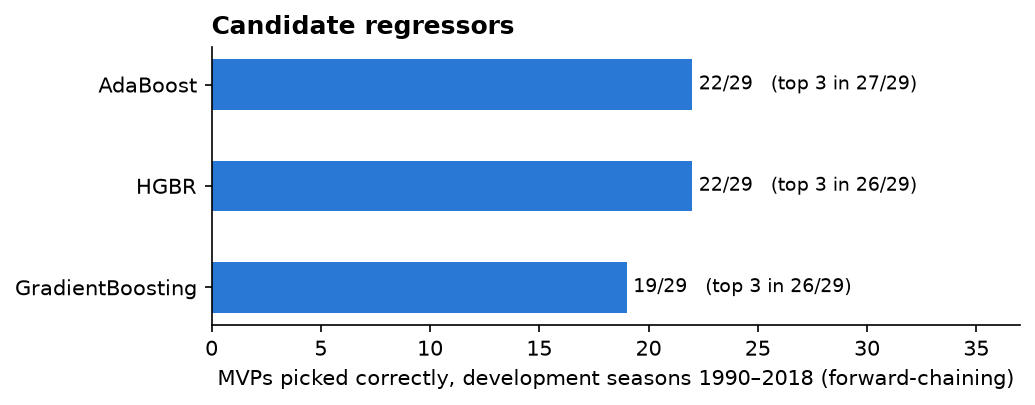

In [14]:
#candidate regressors side by side: MVP picked (bar) and real MVP in the top 3 (label), 1990-2018
import matplotlib.pyplot as plt

summary = pd.DataFrame({name: {'hits': r['Match'].sum(), 'top3': r['Top3'].sum(), 'n': len(r)}
                        for name, r in results_by_model.items()}).T.sort_values('hits')

fig, ax = plt.subplots(figsize=(7, 2.8), dpi=150)
bars = ax.barh(summary.index, summary['hits'], color='#2a78d6', height=0.5)
for b, (name, row) in zip(bars, summary.iterrows()):
    ax.text(row['hits'] + 0.3, b.get_y() + b.get_height() / 2,
            f"{row['hits']}/{row['n']}   (top 3 in {row['top3']}/{row['n']})", va='center', fontsize=9)
ax.set_xlim(0, summary['n'].max() + 8)
ax.set_xlabel('MVPs picked correctly, development seasons 1990–2018 (forward-chaining)')
ax.set_title('Candidate regressors', loc='left', fontweight='bold')
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(OUT / 'regressor_candidates.png', facecolor='white')
plt.show()

**Model choice (regressor):** HistGradientBoostingRegressor on candidates_10, with the settings from the forward-chained search above (`misc/joblib/tuned_hgbr_model.joblib`). It picks the MVP in 22/29 development seasons (1990–2018). AdaBoost ties it (22/29) but takes far longer to tune and fit. Since the candidates are this close, we chose the fastest and simplest of the tied models.

Note: these searches choose settings by vote-share error (mean squared error), not by MVP hits, so the hit counts above are a check on the chosen models rather than the tuning target.